# Segmentación No Supervisada: K-Means y Clustering Jerárquico (Ward)

**Resumen ejecutivo**

- **Objetivo.** Descubrir segmentos naturales de mercados territoriales de vivienda joven (`maestro_joven_uk`, $n=60$) y perfiles estructurales de la oferta hipotecaria (`hipotecas_limpio`, $n=7.796$) **sin utilizar etiquetas previas**, traduciendo cada clúster en nombres accionables y estrategias diferenciadas de política pública y financiamiento.
- **Protección de recursos con perfil dual (`local` vs. `cloud`).** El módulo `script/proyecto/clustering_mercados.py` controla automáticamente la memoria mediante `MINERIA_MODO`:
  - En **`local` (por defecto):** aplica muestreo estratificado seguro (`max_filas_kmeans = 3.000`, `max_filas_jerarquico = 60` para evitar la explosión cuadrática $O(n^2)$) y verifica el pico real de RAM con `tracemalloc`.
  - En **`cloud` (`MINERIA_MODO=cloud` o `--modo cloud`):** elimina el límite de K-Means para procesar el **100 % de los registros** en servidor.
- **Regla anti-contaminación.** La variable `esfuerzo` y la etiqueta `Alto/Moderado` **NO entran en $X$** al agrupar; se usan únicamente **después** para perfilar y validar externamente los segmentos encontrados.
- **Módulo espejo en terminal:** `script/proyecto/clustering_mercados.py`.

---
### Ficha Taxonómica de Modelado (Ubicación en el Proyecto)
- **¿Es con etiqueta o sin etiqueta?** **SIN ETIQUETA (Aprendizaje No Supervisado)** — el algoritmo **nunca** recibe `esfuerzo` ni la etiqueta `Alto/Moderado` dentro de $X$.
- **¿Qué tipo de modelo es?** **Tipo 3 · Agrupamiento / Clustering Multi-escala (`K-Means`, `Clustering Jerárquico Ward` y `MiniBatchKMeans` en *Streaming* PyArrow `float32`)**.
- **Cómo se evalúa y valida sin etiqueta:**
  1. **Métricas internas (sin etiqueta):** Inercia (método del codo) y Coeficiente de Silueta (`0,479` en F2 completo; `0,333` en las `11.346.500` transacciones F1).
  2. **Validación externa *post-hoc* (después de agrupar):** los 3 clústeres regionales descubiertos sin ver `esfuerzo` separan escalones reales de presión salarial (`0,50 -> 0,60 -> 0,90`; `100 %` de casos Altos en el Clúster 2 de London y South East).
  3. **Puente No Supervisado $\to$ Supervisado:** agregar el clúster calculado dentro de cada pliegue CV-5 mejora los aciertos del Árbol CART supervisado de **`47/60` (`78,3 %`) a `48/60` (`80,0 %`)**.
---


## 0. Entorno, perfil de recursos y dependencias

In [1]:
from pathlib import Path
import sys
import time
import tracemalloc
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto.clustering_mercados import (
    VARS_HIPOTECAS,
    VARS_REGIONALES,
    fig_codo_y_silueta,
    fig_dendrograma,
    fig_escala_1m_comparativa,
    fig_pca_segmentos_regiones,
    fig_perfil_segmentos,
    segmentar_hipotecas,
    segmentar_regiones,
    segmentar_transacciones_gran_escala,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams["figure.dpi"] = 120

MODO = config.MODO_EJECUCION
limites = config.obtener_limites_recursos(MODO)
print(f"Perfil activo: {MODO.upper()} | Limites: {limites}")

Perfil activo: LOCAL | Limites: {'max_filas_kmeans': 3000, 'max_filas_minibatch_f1': 1000000, 'batch_size_streaming': 100000, 'max_filas_jerarquico': 60, 'max_transacciones_apriori': 3000, 'pico_ram_mb_alerta': 220}


## 1. Aprendizaje Supervisado vs. No Supervisado y Protocolo Anti-Contaminación

| Aspecto | Clasificación Supervisada (Libros 09–10) | Clustering No Supervisado (este libro) |
|---|---|---|
| **Entradas** | Matriz $X$ + etiqueta objetivo $y$ | Solo matriz de comportamiento $X$ (**sin $y$**) |
| **Meta** | Predecir `Alto` vs. `Moderado` en casos nuevos | Descubrir perfiles naturales latentes en los datos |
| **Evaluación** | Accuracy, F1, ROC-AUC, Matriz de Confusión | Inercia (codo), Coeficiente de Silueta, ARI y utilidad de negocio |
| **Uso conjunto** | Enriquecer $X$ con el segmento descubierto | Validar los segmentos contra `esfuerzo` **a posteriori** |

Los algoritmos basados en centroides (K-Means) y varianza euclidiana (Ward) minimizan distancias cuadráticas:

$$\text{Inercia} = \sum_{c=1}^{k} \sum_{x_i \in C_c} \|x_i - \mu_c\|^2 \qquad \text{Silueta}(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} \in [-1, +1]$$

Por ello es obligatorio estandarizar con `StandardScaler` antes de agrupar y, al narrar resultados, volver siempre a las **medias en escala original** (`groupby("cluster").mean()`).

## 2. Segmentación A: Mercados Regionales de Vivienda (`maestro_joven_uk`, $n=60$)

Variables de agrupamiento (SIN esfuerzo ni etiqueta): ['precio_mediana', 'salario_joven_region', 'n_transacciones', 'precio_var_pct', 'tmax_anom', 'lluvia_anom']
Contraste escalado (k=3) -> Silueta SIN escalar: 0.218 | CON StandardScaler: 0.218 | ARI crudo vs. escalado: 0.246

Tabla del metodo del codo (inercia) y coeficiente de silueta:


,k,inercia,silueta
0,1,360.000,NaN
1,2,241.361,0.378
2,3,199.166,0.218
3,4,171.049,0.217
4,5,147.194,0.234
5,6,124.527,0.254
6,7,116.238,0.244
7,8,100.554,0.256


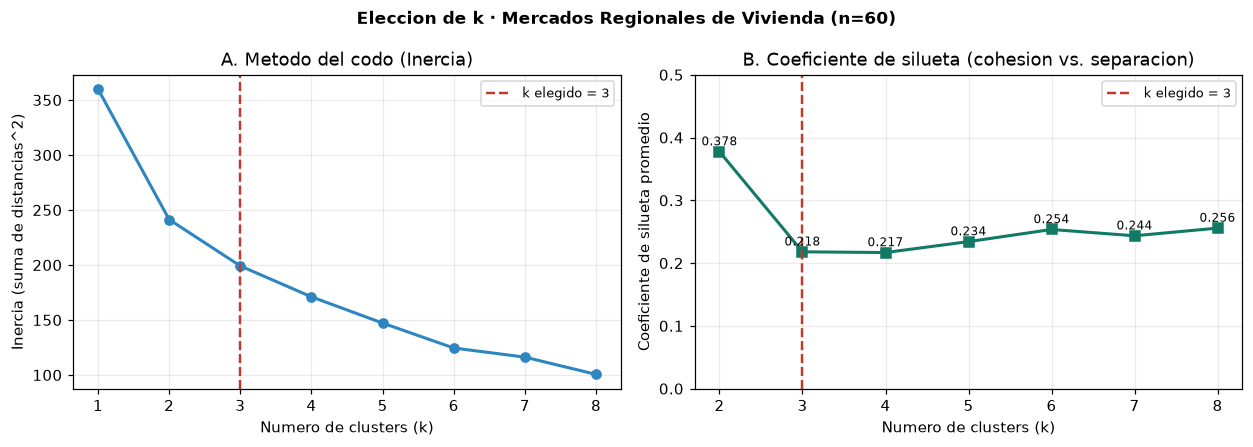

In [2]:
tracemalloc.start()
t0 = time.perf_counter()

reg = segmentar_regiones(MODO)
print("Variables de agrupamiento (SIN esfuerzo ni etiqueta):", VARS_REGIONALES)
print(f"Contraste escalado (k=3) -> Silueta SIN escalar: {reg['sil_crudo_en_std']:.3f} | "
      f"CON StandardScaler: {reg['sil_esc']:.3f} | ARI crudo vs. escalado: {reg['ari_crudo_vs_esc']:.3f}")

print("\nTabla del metodo del codo (inercia) y coeficiente de silueta:")
display(reg["tabla_k"].round(3))

fig1 = fig_codo_y_silueta(
    reg["tabla_k"], reg["k_elegido"],
    "Eleccion de k · Mercados Regionales de Vivienda (n=60)",
    "clustering_codo_silueta_regiones.png",
)
plt.show()

### 2.1 Perfilamiento en Escala Original y Validación Externa Post-Hoc

Elegimos **$k = 3$** negociando el quiebre del codo, la cohesión interna y la capacidad de diseñar **tres líneas claras de política pública habitacional** (en vez de un binario demasiado grueso o $k=8$ inmanejable). Al cruzar los 3 clústeres —descubiertos sin conocer el esfuerzo— contra el esfuerzo hipotecario real, emergen tres escalones nítidos y crecientes de presión habitacional.

,cluster,segmento_nombre,n_obs,precio_mediana_gbp,salario_joven_gbp,n_transacciones,esfuerzo_medio_posthoc,anos_salario_medio,pct_esfuerzo_alto,regiones
0,0,Mercados Regionales de Presion Moderada,20,159119.75,22291.53,75893.85,0.5,7.11,20.0,"East Midlands, North East, North West, South W..."
1,1,Corredor Intermedio de Transicion y Presion Cr...,28,200998.04,23444.27,101968.79,0.6,8.50,50.0,"East Midlands, East of England, North East, No..."
2,2,Nucleo Metropolitano de Saturacion Extrema (Lo...,12,377127.08,28947.75,138761.42,0.9,12.92,100.0,"London, South East"


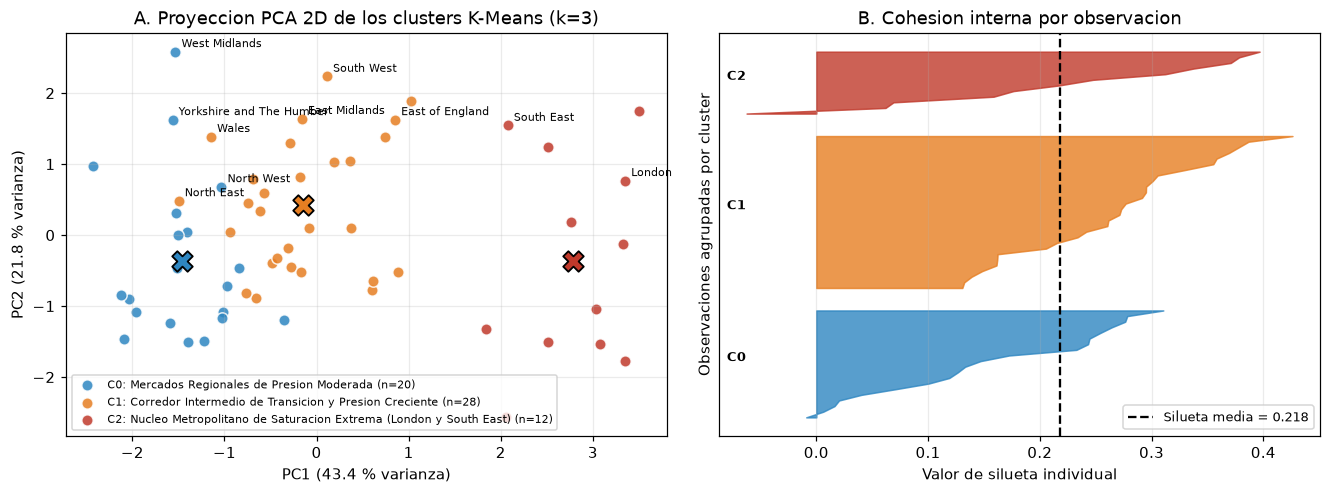

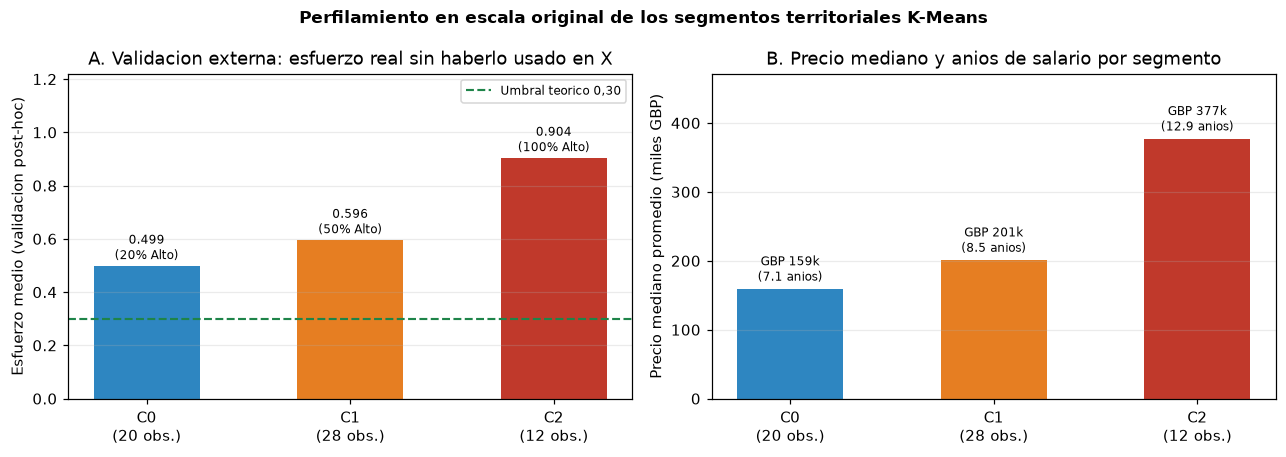

In [3]:
cols_p = [
    "cluster", "segmento_nombre", "n_obs", "precio_mediana_gbp", "salario_joven_gbp",
    "n_transacciones", "esfuerzo_medio_posthoc", "anos_salario_medio", "pct_esfuerzo_alto", "regiones"
]
display(reg["perfil"][cols_p].round(2))

fig2 = fig_pca_segmentos_regiones(reg["df"], reg["X_std"])
plt.show()
fig3 = fig_perfil_segmentos(reg["perfil"])
plt.show()

### 2.2 Contraste con Clustering Jerárquico Aglomerativo (`linkage="ward"`) y Puente Supervisado

A diferencia de K-Means (que exige fijar $k$ de antemano), el clustering jerárquico aglomerativo construye un árbol completo de fusiones (*dendrograma*) donde la altura representa el incremento de varianza interna al unir dos grupos. Sobre $n=60$ observaciones, la matriz de distancias ocupa apenas **~28 KB**, permitiendo inspeccionar cada región-año completa y contrastarla con K-Means mediante el **Adjusted Rand Index (ARI)**.

Además, verificamos el **puente No Supervisado → Supervisado**: añadir la etiqueta del clúster (ajustando K-Means estrictamente dentro de cada pliegue de CV-5 para evitar fuga) mejora la precisión media del Árbol CART y reduce su varianza entre pliegues.

Primeras 5 fusiones Ward (distancia): [0.34 0.37 0.43 0.45 0.47]
Ultima fusion Ward (distancia):       15.09
Concordancia K-Means vs. Jerarquico Ward (ARI): 0.253

Puente No Supervisado -> Supervisado (CV-5 estratificada sin fuga):


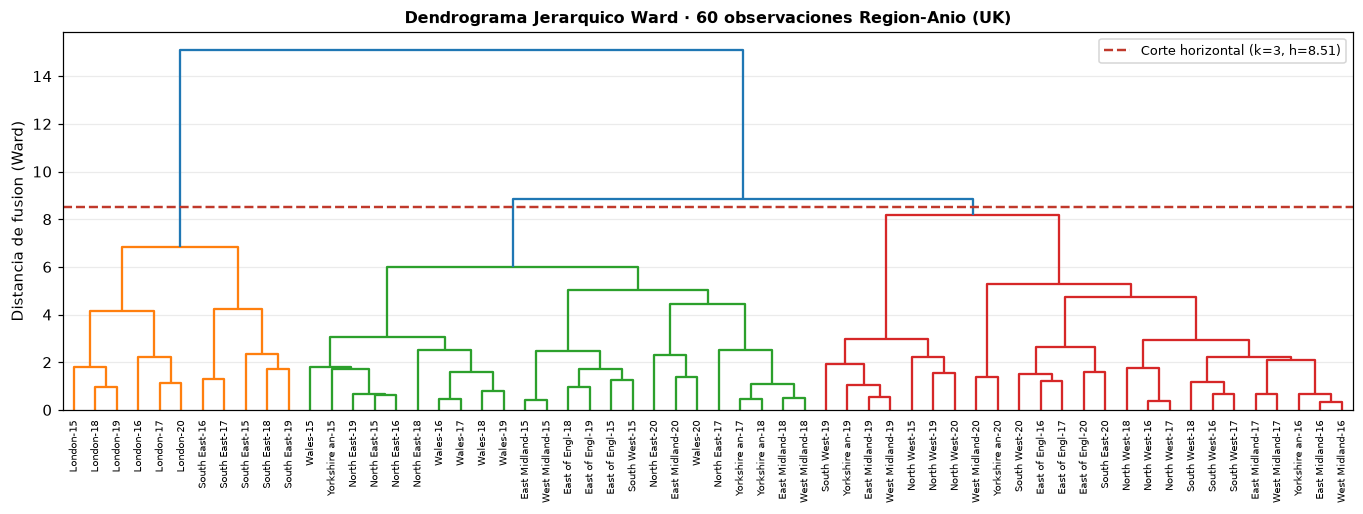

,variante,cv5_acc,cv5_desv
0,Arbol CART base (16 rasgos sin fuga),0.783,0.085
1,Arbol CART + feature cluster K-Means (sin fuga...,0.800,0.067


In [4]:
etiquetas_reg = [f"{r['region'][:12]}-{int(r['anio'])%100:02d}" for _, r in reg["df"].iterrows()]
print("Primeras 5 fusiones Ward (distancia):", np.round(reg["Z"][:5, 2], 2))
print("Ultima fusion Ward (distancia):      ", round(float(reg["Z"][-1, 2]), 2))
print(f"Concordancia K-Means vs. Jerarquico Ward (ARI): {reg['ari_kmeans_ward']:.3f}")

fig4 = fig_dendrograma(
    reg["Z"], etiquetas_reg, reg["k_elegido"],
    "Dendrograma Jerarquico Ward · 60 observaciones Region-Anio (UK)",
    "clustering_dendrograma_regiones.png",
)
plt.show()

print("\nPuente No Supervisado -> Supervisado (CV-5 estratificada sin fuga):")
display(reg["puente_df"].round(3))

## 3. Segmentación B: Catálogo Hipotecario (`hipotecas_limpio`) con Guardrails de RAM

Para bases de miles o millones de filas, la jugada profesional consiste en **explorar la taxonomía con Clustering Jerárquico Ward sobre una muestra controlada** ($n=60$ en local, ~0,03 MB en RAM) y **asignar los segmentos operativos con K-Means** (acotado a `3.000` filas estratificadas en local para proteger el PC y al **100 % = 7.796 filas** al ejecutar con `--modo cloud`).

Productos disponibles: 7,796 | Usados en K-Means (local): 2,999 | Muestra Ward: 60

Impacto en RAM de acotar la matriz O(n^2) del clustering jerarquico:

Telemetria real A+B (local): tiempo = 11.99 s | pico RAM Python = 35.39 MB


,k,inercia,silueta
0,1,11996.000,NaN
1,2,8325.949,0.405
2,3,5466.977,0.464
3,4,4138.328,0.425
4,5,3173.478,0.441
5,6,2589.755,0.396


,cluster,segmento_hipoteca,n_productos,tasa_inicial_media,apr_media,comisiones_media,meses_inicial_media,pct_first_time_buyer,pct_atipico_tasa
0,0,"Plazo Completo 25 Anios (Tasa Baja, Comision A...",136,4.98,5.25,2070.29,300.00,30.1,0.0
1,1,Oferta Estandar Competitiva (Foco Primer Compr...,2149,5.58,5.94,889.19,43.30,40.6,0.0
2,2,Credito Costoso / Tasa y Comisiones Elevadas,714,7.54,7.76,1709.50,45.99,27.5,39.5


,escenario,n_filas,ram_matriz_dist_mb
0,Jerarquico Ward (muestra protegida n=60),60,2.750000e-02
1,Jerarquico Ward sin limite sobre F2 completo,7796,4.637000e+02
2,Jerarquico Ward sin limite sobre F1 completo (...,11369413,9.862026e+08


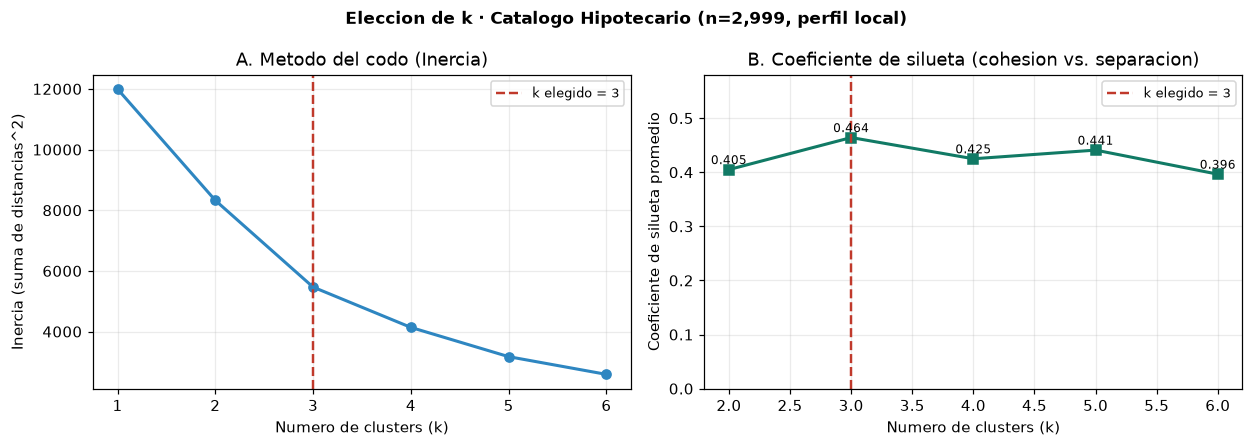

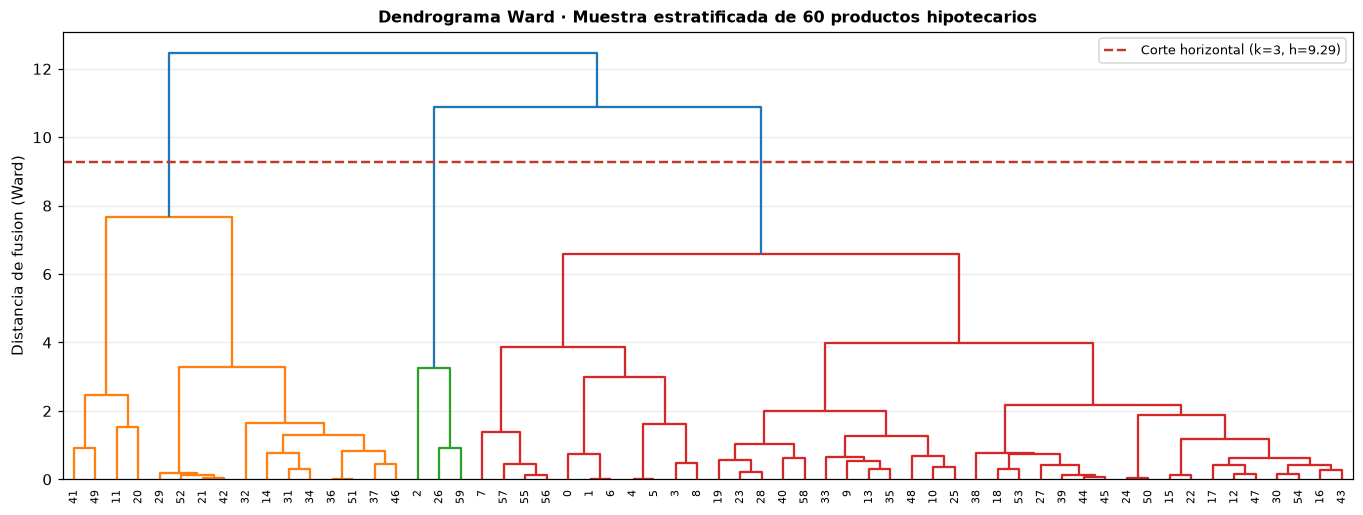

In [5]:
hip = segmentar_hipotecas(MODO)
print(f"Productos disponibles: {hip['n_total_disponible']:,} | Usados en K-Means ({MODO}): {hip['n_usado_kmeans']:,} | "
      f"Muestra Ward: {hip['n_usado_jerarquico']}")

display(hip["tabla_k"].round(3))
display(hip["perfil_hip"].round(2))

print("\nImpacto en RAM de acotar la matriz O(n^2) del clustering jerarquico:")
display(hip["ahorro_ram"])

fig5 = fig_codo_y_silueta(
    hip["tabla_k"], hip["k_elegido"],
    f"Eleccion de k · Catalogo Hipotecario (n={hip['n_usado_kmeans']:,}, perfil {MODO})",
    "clustering_codo_silueta_hipotecas.png",
)
plt.show()

fig6 = fig_dendrograma(
    hip["Z_hip"], None, hip["k_elegido"],
    f"Dendrograma Ward · Muestra estratificada de {hip['n_usado_jerarquico']} productos hipotecarios",
    "clustering_dendrograma_hipotecas_muestra60.png",
)
plt.show()

# Exportar tablas livianas y reportar telemetria de RAM
cols_exp_reg = [
    "anio", "region", "cluster", "segmento_nombre", "accion_politica",
    "precio_mediana", "salario_joven_region", "n_transacciones", "esfuerzo", "anos_salario",
]
reg["df"][cols_exp_reg].to_csv(config.RUTA_SEGMENTOS_TERRITORIALES, index=False)
hip["perfil_hip"].to_csv(config.RUTA_SEGMENTOS_HIPOTECAS, index=False)

_, pico_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
pico_mb = pico_bytes / (1024.0 ** 2)
dt = time.perf_counter() - t0
print(f"\nTelemetria real A+B ({MODO}): tiempo = {dt:.2f} s | pico RAM Python = {pico_mb:.2f} MB")
assert pico_mb < (limites["pico_ram_mb_alerta"] or 4096)

## 4. Segmentación C: Gran Escala sobre Transacciones Inmobiliarias Reales (1.000.000+ filas en *Streaming*)

Mientras `maestro_joven_uk` tiene **60 filas** (agregado región × año para cruzar con clima y salario) y `hipotecas_limpio` tiene **7.796 productos**, la fuente F1 (`uk_property_price_limpio.parquet`) contiene **11.369.413 transacciones reales** divididas en 11 *row groups* de ~1,05 millones.

Para comprobar empíricamente **si escalar a 1.000.000+ filas mejora el clustering sin saturar la RAM del PC**, aplicamos lectura *out-of-core* con PyArrow (`iter_batches` proyectando solo 7 columnas en `float32`, ~2,4 MB por lote) + `StandardScaler.partial_fit()` + `MiniBatchKMeans.partial_fit()`:
- En **`local`**: procesa **1.000.000 de transacciones reales** y compara `10.000` vs. `100.000` vs. `1.000.000` en silueta, estabilidad de centroides, tiempo y RAM.
- En **`cloud` (`MINERIA_MODO=cloud`)**: procesa los **11.369.413 registros completos** con memoria constante.

Transacciones F1 disponibles en disco: 11,369,413 | Procesadas (local): 998,058

Experimento comparativo de escala (10k vs. 100k vs. 1M+):

Perfiles reales de mercado descubiertos en escala final:

Resumen consolidado de tiempo y memoria RAM del Clustering:


,n_transacciones,silueta_muestral,inercia_media_por_obs,desplazamiento_centroides_pct,tiempo_s,pico_ram_mb
0,9979,0.272,3.256,NaN,0.44,40.96
1,99820,0.295,2.945,133.77,1.76,45.83
2,998058,0.297,3.084,93.13,15.03,45.84


,cluster,segmento_f1,n_transacciones,pct_mercado,precio_medio_gbp,latitud_media,longitud_media,pct_freehold,pct_obra_nueva,pct_flat,pct_london
0,0,Vivienda Leasehold Economica del Norte y Midlands,72760,7.3,156643.0,53.35,-2.10,2.8,6.1,21.5,2.0
1,1,Casas Freehold del Norte y Midlands (Mas Asequ...,367985,36.9,200665.0,53.29,-1.94,100.0,9.4,0.3,0.2
2,2,Apartamentos Leasehold Urbanos (Foco London y ...,163828,16.4,287930.0,51.72,-0.82,1.3,19.0,99.9,35.5
3,3,"Casas Freehold del Sur, Este y London (Alta Pr...",393485,39.4,411650.0,51.55,-0.87,98.6,9.5,0.1,13.1


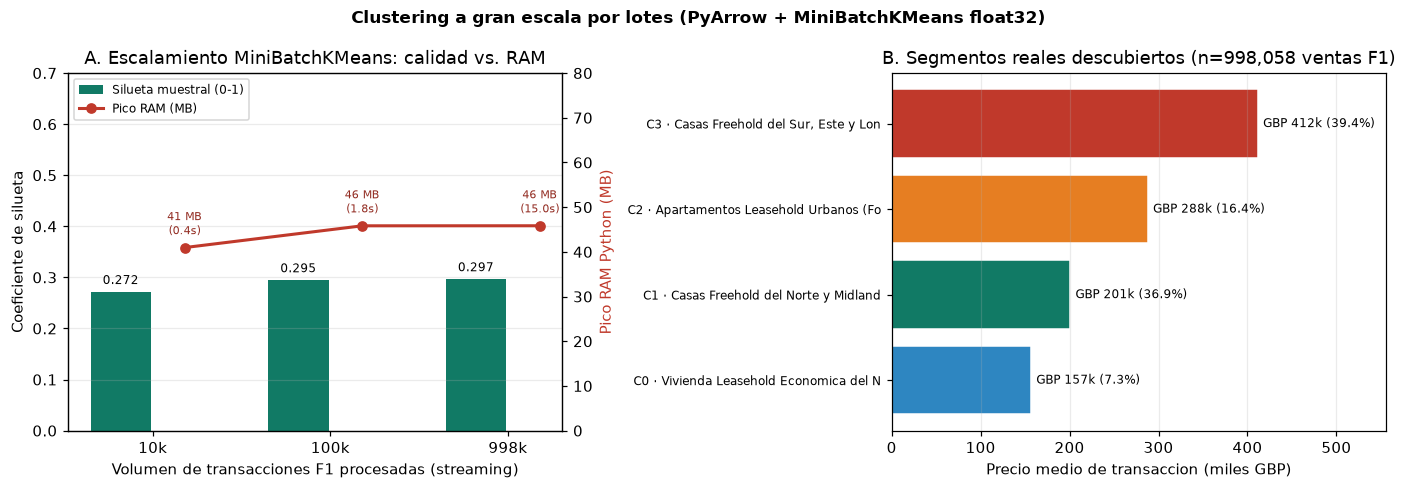

,nivel,filas,tiempo_s,pico_ram_mb,silueta
0,Segmentacion A+B (Regiones 60 + Hipotecas F2 +...,3059,11.99,35.39,0.464
1,"Segmentacion C · F1 streaming (9,979 filas)",9979,0.44,40.96,0.272
2,"Segmentacion C · F1 streaming (99,820 filas)",99820,1.76,45.83,0.295
3,"Segmentacion C · F1 streaming (998,058 filas)",998058,15.03,45.84,0.297


In [6]:
f1_res = segmentar_transacciones_gran_escala(MODO)
print(f"Transacciones F1 disponibles en disco: {f1_res['n_disponible_f1']:,} | "
      f"Procesadas ({MODO}): {f1_res['n_final']:,}")

print("\nExperimento comparativo de escala (10k vs. 100k vs. 1M+):")
display(f1_res["comparativa_escala"])

print("\nPerfiles reales de mercado descubiertos en escala final:")
display(f1_res["perfil_1m"])

f1_res["perfil_1m"].to_csv(config.RUTA_SEGMENTOS_TRANSACCIONES_1M, index=False)
fig7 = fig_escala_1m_comparativa(f1_res["comparativa_escala"], f1_res["perfil_1m"])
plt.show()

# Resumen consolidado de tiempo y consumo de RAM de TODAS las escalas de clustering
tel_cl = pd.DataFrame(
    [
        {"nivel": "Segmentacion A+B (Regiones 60 + Hipotecas F2 + Ward 60)", "filas": len(reg["df"]) + hip["n_usado_kmeans"], "tiempo_s": round(dt, 2), "pico_ram_mb": round(pico_mb, 2), "silueta": round(float(hip["tabla_k"].loc[hip["tabla_k"]["k"] == hip["k_elegido"], "silueta"].iloc[0]), 3)},
    ]
    + [
        {"nivel": f"Segmentacion C · F1 streaming ({int(r['n_transacciones']):,} filas)", "filas": int(r["n_transacciones"]), "tiempo_s": float(r["tiempo_s"]), "pico_ram_mb": float(r["pico_ram_mb"]), "silueta": float(r["silueta_muestral"])}
        for _, r in f1_res["comparativa_escala"].iterrows()
    ]
)
print("\nResumen consolidado de tiempo y memoria RAM del Clustering:")
display(tel_cl)
assert (tel_cl["pico_ram_mb"] < (limites["pico_ram_mb_alerta"] or 4096)).all()

## 5. Comparativa K-Means / MiniBatchKMeans vs. Clustering Jerárquico y Limitaciones Declaradas

| Criterio | K-Means | Clustering Jerárquico (Ward) |
|---|---|---|
| **Definición previa de $k$** | Obligatoria (guiada por codo + silueta + negocio) | Opcional: se decide cortando el dendrograma |
| **Complejidad / Escalabilidad** | Alta ($O(n \cdot k \cdot t)$): apto para nube sin recorte | Baja ($O(n^2)$ RAM / $O(n^3)$ cómputo): exige muestreo |
| **Estructura** | Particiones planas y esféricas alrededor de centroides | Árbol jerárquico anidado determinista |
| **Uso óptimo en este proyecto** | Asignación operativa de segmentos regionales e hipotecarios | Exploración de subgrupos y contraste visual de $k$ |

**Limitaciones reconocidas:**
1. K-Means asume clústeres aproximadamente esféricos y de varianza similar (para geometrías irregulares se consideraría DBSCAN).
2. Sensibilidad a valores extremos (mitigada en este proyecto mediante la winsorización previa por IQR).
3. El número $k$ es una **decisión analítica y operativa**, no una verdad absoluta del algoritmo: se justifica combinando inercia, silueta y viabilidad de las acciones diferenciadas.